# Indian Pre-Owned Car Price Prediction

**Goal:** build an end-to-end regression pipeline that predicts the resale **Price** of a used car in India, then deploy it in a Streamlit application (`app.py` in the project root).

**Pipeline at a glance**

| Stage | What we do |
|---|---|
| 1. Data understanding | Load train/test/sample-submission, check shapes and dtypes |
| 2. EDA | Missing values, outliers, distributions, correlations, categorical effects |
| 3. Preprocessing | Structural fixes, imputation, feature engineering, encoding (`car_utils.CarPreprocessor`) |
| 4. Modelling | Baselines → Ridge, Random Forest, XGBoost, LightGBM → 5-fold CV → hyper-parameter tuning |
| 5. Evaluation | RMSE, MAE, R² on a hold-out set + residual & segment analysis |
| 6. Deliverables | `outputs/submission.csv` for the Test set + `models/car_price_model.joblib` for Streamlit |

> **Design choice:** all cleaning/feature code lives in `car_utils.py` (project root), imported here *and* in the app. That guarantees identical preprocessing in training and production.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Project folders. The notebook lives in notebooks/, so the project root is one level up.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))          # makes `car_utils` importable
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR.mkdir(exist_ok=True); OUTPUT_DIR.mkdir(exist_ok=True)

import warnings, time, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from car_utils import (load_data, CarPreprocessor, regression_report,
                       MAX_DISPLACEMENT_CC, MAX_POWER, MAX_DISTANCE_KM)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 200)
pd.options.display.float_format = "{:,.2f}".format
RANDOM_STATE = 42

## 1. Load the data

In [2]:
train = load_data(f"{DATA_DIR}/Cap_Training_Data_2025.csv")
test  = load_data(f"{DATA_DIR}/Cap_Test_Data_2025.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/Cap_Sample_Submission_2025.csv")

print("Train :", train.shape)
print("Test  :", test.shape)
print("Sample submission:", sample_sub.shape, "->", list(sample_sub.columns))
train.head()

Train : (53515, 17)
Test  : (5615, 16)
Sample submission: (5615, 2) -> ['ID', 'Price']


,ID,Maker,model,Location,Distance,Owner Type,manufacture_year,Age of car,engine_displacement,engine_power,body_type,Vroom Audit Rating,transmission,door_count,seat_count,fuel_type,Price
0,11100001,skoda,octavia,Ahmedabad,NaN,Second,"1,973.00",52,1964,147.00,compact,8,man,NaN,NaN,petrol,"543,764.25"
1,11100002,fiat,panda,Ahmedabad,"27,750.00",Third,"2,021.00",4,1242,51.00,NaN,6,man,4.00,4.00,petrol,"401,819.25"
2,11100003,bmw,x1,Hyderabad,"46,000.00",Third,"2,023.00",2,1995,105.00,NaN,7,auto,4.00,5.00,diesel,"2,392,855.50"
3,11100004,nissan,juke,Mumbai,"43,949.00",Third,"2,020.00",5,1618,140.00,NaN,7,man,4.00,5.00,petrol,"958,606.50"
4,11100005,bmw,x5,Jaipur,"59,524.00",Fourth & Above,"2,021.00",4,2993,180.00,NaN,7,auto,4.00,5.00,diesel,"3,085,561.50"


**Note (a first data-quality catch):** the raw header is `'Distance '` — with a trailing space. `load_data()` strips whitespace from all column names so `df['Distance']` works everywhere.

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 53515 entries, 0 to 53514
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   53515 non-null  int64  
 1   Maker                53515 non-null  str    
 2   model                53515 non-null  str    
 3   Location             53509 non-null  str    
 4   Distance             52304 non-null  float64
 5   Owner Type           53515 non-null  str    
 6   manufacture_year     53513 non-null  float64
 7   Age of car           53515 non-null  int64  
 8   engine_displacement  53515 non-null  int64  
 9   engine_power         52076 non-null  float64
 10  body_type            4136 non-null   str    
 11  Vroom Audit Rating   53515 non-null  int64  
 12  transmission         53515 non-null  str    
 13  door_count           45981 non-null  float64
 14  seat_count           45004 non-null  float64
 15  fuel_type            53515 non-null  str    
 1

In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"53,515.00","11,126,758.00","15,448.59","11,100,001.00","11,113,379.50","11,126,758.00","11,140,136.50","11,153,515.00"
Distance,"52,304.00","94,546.26","275,561.72",0.00,"15,490.00","65,520.00","135,641.00","9,899,800.00"
manufacture_year,"53,513.00","2,019.41",4.65,"1,943.00","2,017.00","2,020.00","2,023.00","2,025.00"
Age of car,"53,515.00",5.59,4.65,0.00,2.00,5.00,8.00,82.00
engine_displacement,"53,515.00","1,904.05","1,496.56",14.00,"1,395.00","1,896.00","1,995.00","32,000.00"
engine_power,"52,076.00",100.45,45.33,10.00,73.00,91.00,125.00,896.00
Vroom Audit Rating,"53,515.00",6.00,1.42,4.00,5.00,6.00,7.00,8.00
door_count,"45,981.00",3.97,0.74,1.00,4.00,4.00,4.00,6.00
seat_count,"45,004.00",4.89,0.56,1.00,5.00,5.00,5.00,9.00
Price,"53,515.00","1,098,083.51","844,156.53",3.00,"505,181.25","885,455.25","1,477,828.88","22,120,775.25"


## 2. Exploratory Data Analysis

### 2.1 Missing-value analysis

,train_missing,train_%,test_missing,test_%
body_type,49379,92.27,5193,92.48
seat_count,8511,15.90,891,15.87
door_count,7534,14.08,806,14.35
engine_power,1439,2.69,168,2.99
Distance,1211,2.26,128,2.28
Location,6,0.01,0,0.00
manufacture_year,2,0.00,0,0.00
Price,0,0.00,5615,100.00


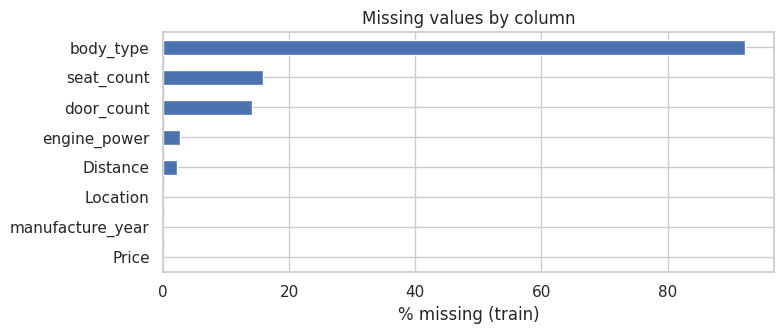

In [5]:
miss = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_%": train.isna().mean() * 100,
    "test_missing": test.reindex(columns=train.columns).isna().sum(),
    "test_%": test.reindex(columns=train.columns).isna().mean() * 100,
}).query("train_missing > 0 or test_missing > 0").sort_values("train_%", ascending=False)
display(miss)

fig, ax = plt.subplots(figsize=(8, 3.5))
miss["train_%"].plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("% missing (train)"); ax.set_title("Missing values by column"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**Findings**
- `body_type` is ~92% empty and only has values `compact` / `van`. A blank almost certainly means *"standard body"* rather than *"unknown"*, so we treat it as its own level instead of dropping/imputing it.
- `Distance`, `engine_power`, `door_count`, `seat_count` have modest gaps (2–16%) → group-wise imputation.
- `Location` (6 rows) and `manufacture_year` (2 rows) are negligible. `manufacture_year` is fully redundant: `manufacture_year + Age of car = 2025` for every non-missing row, so we use `Age of car` (never missing).

In [6]:
print("manufacture_year + Age of car:", (train.manufacture_year + train["Age of car"]).value_counts().to_dict())

manufacture_year + Age of car: {2025.0: 53513}


### 2.2 Target distribution

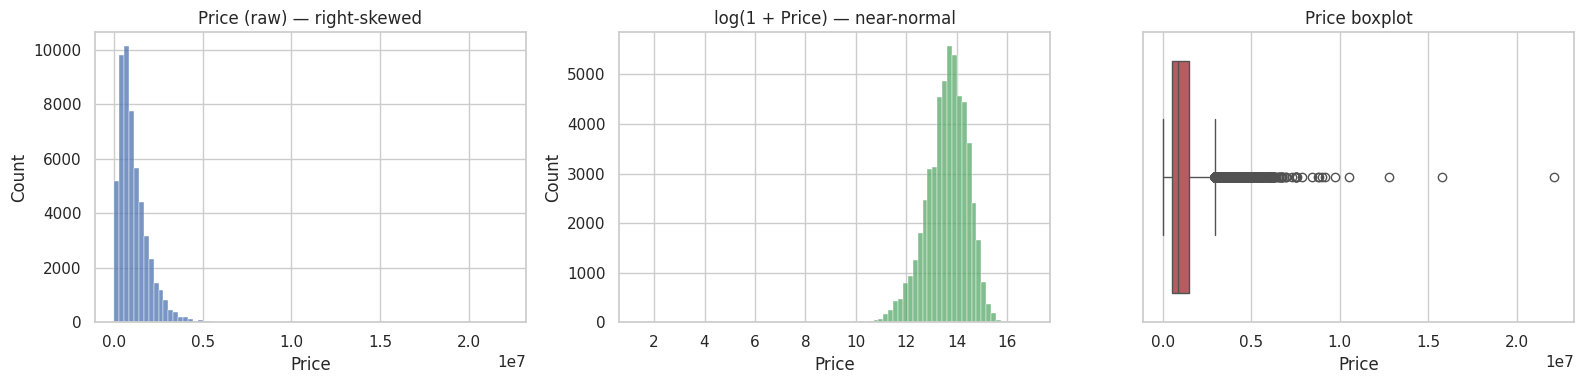

count       53,515.00
mean     1,098,083.51
std        844,156.53
min              3.00
25%        505,181.25
50%        885,455.25
75%      1,477,828.88
max     22,120,775.25
Name: Price, dtype: float64
Skewness raw: 2.18 | log: -1.37


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train.Price, bins=80, ax=axes[0], color="#4c72b0"); axes[0].set_title("Price (raw) — right-skewed")
sns.histplot(np.log1p(train.Price), bins=80, ax=axes[1], color="#55a868"); axes[1].set_title("log(1 + Price) — near-normal")
sns.boxplot(x=train.Price, ax=axes[2], color="#c44e52"); axes[2].set_title("Price boxplot")
plt.tight_layout(); plt.show()
print(train.Price.describe())
print("Skewness raw:", round(train.Price.skew(), 2), "| log:", round(np.log1p(train.Price).skew(), 2))

Price is heavily right-skewed (skew ≈ 4 → about −0.3 after a log transform). **We will train on `log1p(Price)`**, which stabilises variance and makes errors *relative* (a ₹50k miss matters far more on a ₹300k car than on a ₹3M car). Predictions are transformed back to rupees before computing RMSE/MAE/R².

### 2.3 Outlier detection & data-quality issues

,min,median,max,IQR lower fence,IQR upper fence,# outliers (IQR)
feature,,,,,,
Distance,0.00,"65,520.00","9,899,800.00","-164,736.50","315,867.50",548
Age of car,0.00,5.00,82.00,-7.00,17.00,785
engine_displacement,14.00,"1,896.00","32,000.00",495.00,"2,895.00",5651
engine_power,10.00,91.00,896.00,-5.00,203.00,1406
Price,3.00,"885,455.25","22,120,775.25","-953,790.19","2,936,800.31",1948


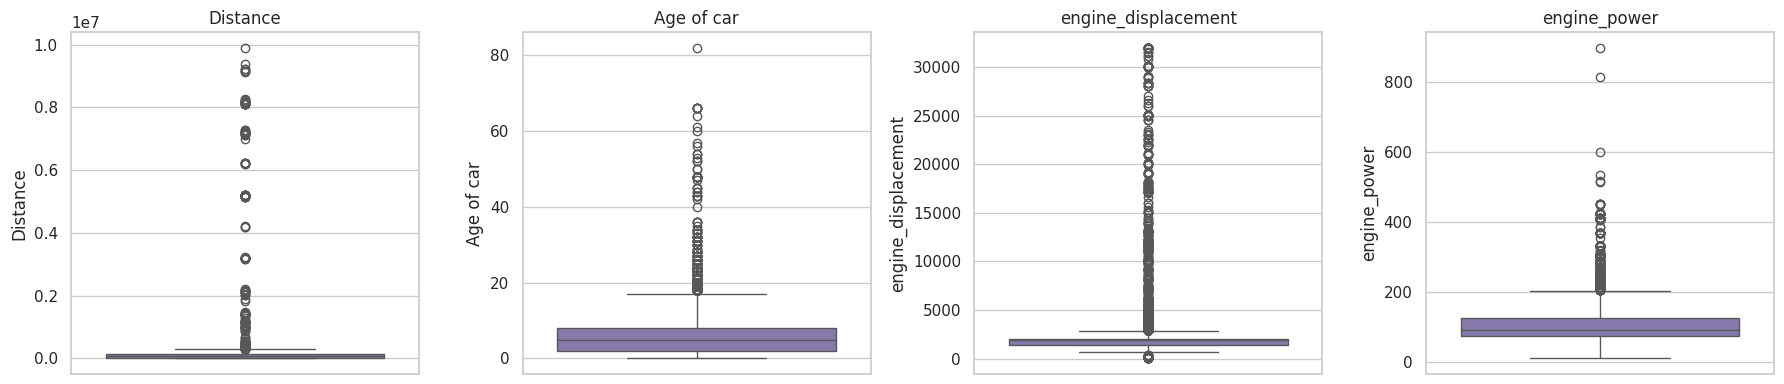

In [8]:
num_cols = ["Distance", "Age of car", "engine_displacement", "engine_power", "Price"]
rows = []
for c in num_cols:
    s = train[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "min": s.min(), "median": s.median(), "max": s.max(),
                 "IQR lower fence": lo, "IQR upper fence": hi,
                 "# outliers (IQR)": int(((s < lo) | (s > hi)).sum())})
display(pd.DataFrame(rows).set_index("feature"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["Distance", "Age of car", "engine_displacement", "engine_power"]):
    sns.boxplot(y=train[c], ax=ax, color="#8172b3"); ax.set_title(c)
plt.tight_layout(); plt.show()

The IQR rule flags a lot of rows, but *statistical* outliers (e.g. a real 4.4 L BMW X5 with 408 kW) are legitimate. We separate them from **impossible values (data-entry errors)**, which are the ones that must be fixed:

In [9]:
issues = pd.Series({
    f"engine_displacement > {MAX_DISPLACEMENT_CC} cc (e.g. 32,000 cc)": (train.engine_displacement > MAX_DISPLACEMENT_CC).sum(),
    "engine_displacement < 600 cc":                                  (train.engine_displacement < 600).sum(),
    f"engine_power > {MAX_POWER}":                                    (train.engine_power > MAX_POWER).sum(),
    f"Distance > {MAX_DISTANCE_KM:,} km (max = {train.Distance.max():,.0f})": (train.Distance > MAX_DISTANCE_KM).sum(),
    "Distance == 0 on a car aged ≥ 2 yrs":                           ((train.Distance == 0) & (train['Age of car'] >= 2)).sum(),
    "Age of car > 30 yrs (vintage, keep)":                           (train['Age of car'] > 30).sum(),
    "Price < ₹20,000":                                               (train.Price < 20000).sum(),
}, name="rows")
display(issues.to_frame())

,rows
"engine_displacement > 6500 cc (e.g. 32,000 cc)",379
engine_displacement < 600 cc,24
engine_power > 500,6
"Distance > 500,000 km (max = 9,899,800)",167
Distance == 0 on a car aged ≥ 2 yrs,49
"Age of car > 30 yrs (vintage, keep)",67
"Price < ₹20,000",37


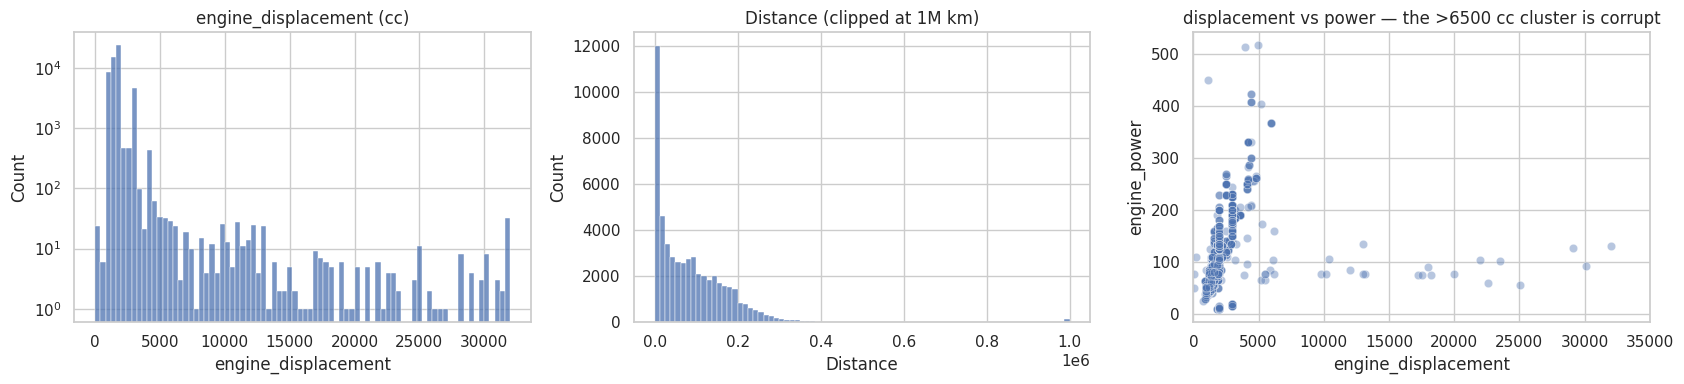

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(train.engine_displacement.clip(upper=35000), bins=80, ax=axes[0]); axes[0].set_title("engine_displacement (cc)")
axes[0].set_yscale("log")
sns.histplot(train.Distance.dropna().clip(upper=1_000_000), bins=80, ax=axes[1]); axes[1].set_title("Distance (clipped at 1M km)")
sns.scatterplot(data=train.sample(6000, random_state=1), x="engine_displacement", y="engine_power", alpha=.4, ax=axes[2])
axes[2].set_xlim(0, 35000); axes[2].set_title("displacement vs power — the >6500 cc cluster is corrupt")
plt.tight_layout(); plt.show()

**Decisions (implemented in `CarPreprocessor._basic_clean`)**

| Issue | Treatment |
|---|---|
| Displacement > 6,500 cc or < 600 cc (looks like extra/missing digits, e.g. 32000) | set to NaN → impute by model & fuel type; keep a flag |
| engine_power > 500 or < 20 | set to NaN → impute |
| Distance > 500,000 km (up to 9.9 M) or negative | set to NaN → impute |
| Distance = 0 on a car ≥ 2 years old | set to NaN (a brand-new car with 0 km is fine, an old one is not) |
| Age > 30 (vintage) | kept — tree models handle it, and prices are sensible |
| Very low prices | kept — a log target makes them harmless |

We *mask and impute* instead of deleting, so no training rows are lost and the **test set gets the same treatment** (it contains the same kinds of corruption).

### 2.4 Numeric relationships with Price

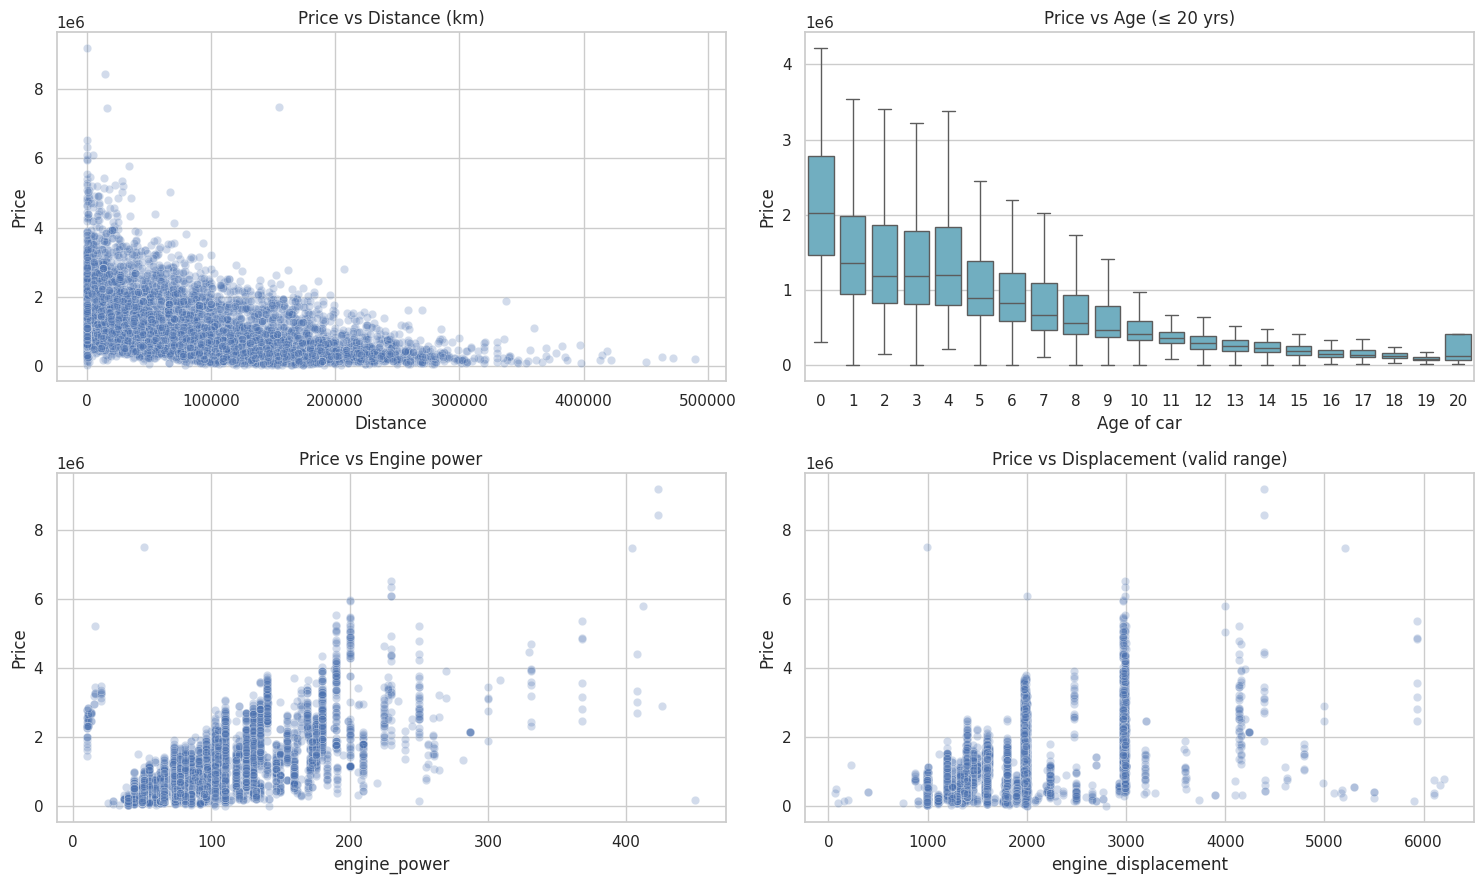

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
s = train.sample(8000, random_state=1)
sns.scatterplot(data=s[s.Distance < 500000], x="Distance", y="Price", alpha=.25, ax=axes[0, 0]); axes[0, 0].set_title("Price vs Distance (km)")
sns.boxplot(data=train[train['Age of car'] <= 20], x="Age of car", y="Price", ax=axes[0, 1], showfliers=False, color="#64b5cd"); axes[0, 1].set_title("Price vs Age (≤ 20 yrs)")
sns.scatterplot(data=s[s.engine_power < 500], x="engine_power", y="Price", alpha=.25, ax=axes[1, 0]); axes[1, 0].set_title("Price vs Engine power")
sns.scatterplot(data=s[s.engine_displacement < 6500], x="engine_displacement", y="Price", alpha=.25, ax=axes[1, 1]); axes[1, 1].set_title("Price vs Displacement (valid range)")
plt.tight_layout(); plt.show()

Price drops steeply in the first 1–3 years (a nearly-new car loses about a third of its value), then decays more slowly; it also falls with mileage and rises with engine power. These are non-linear patterns — a good reason to prefer tree ensembles over plain linear regression.

### 2.5 Categorical features vs Price

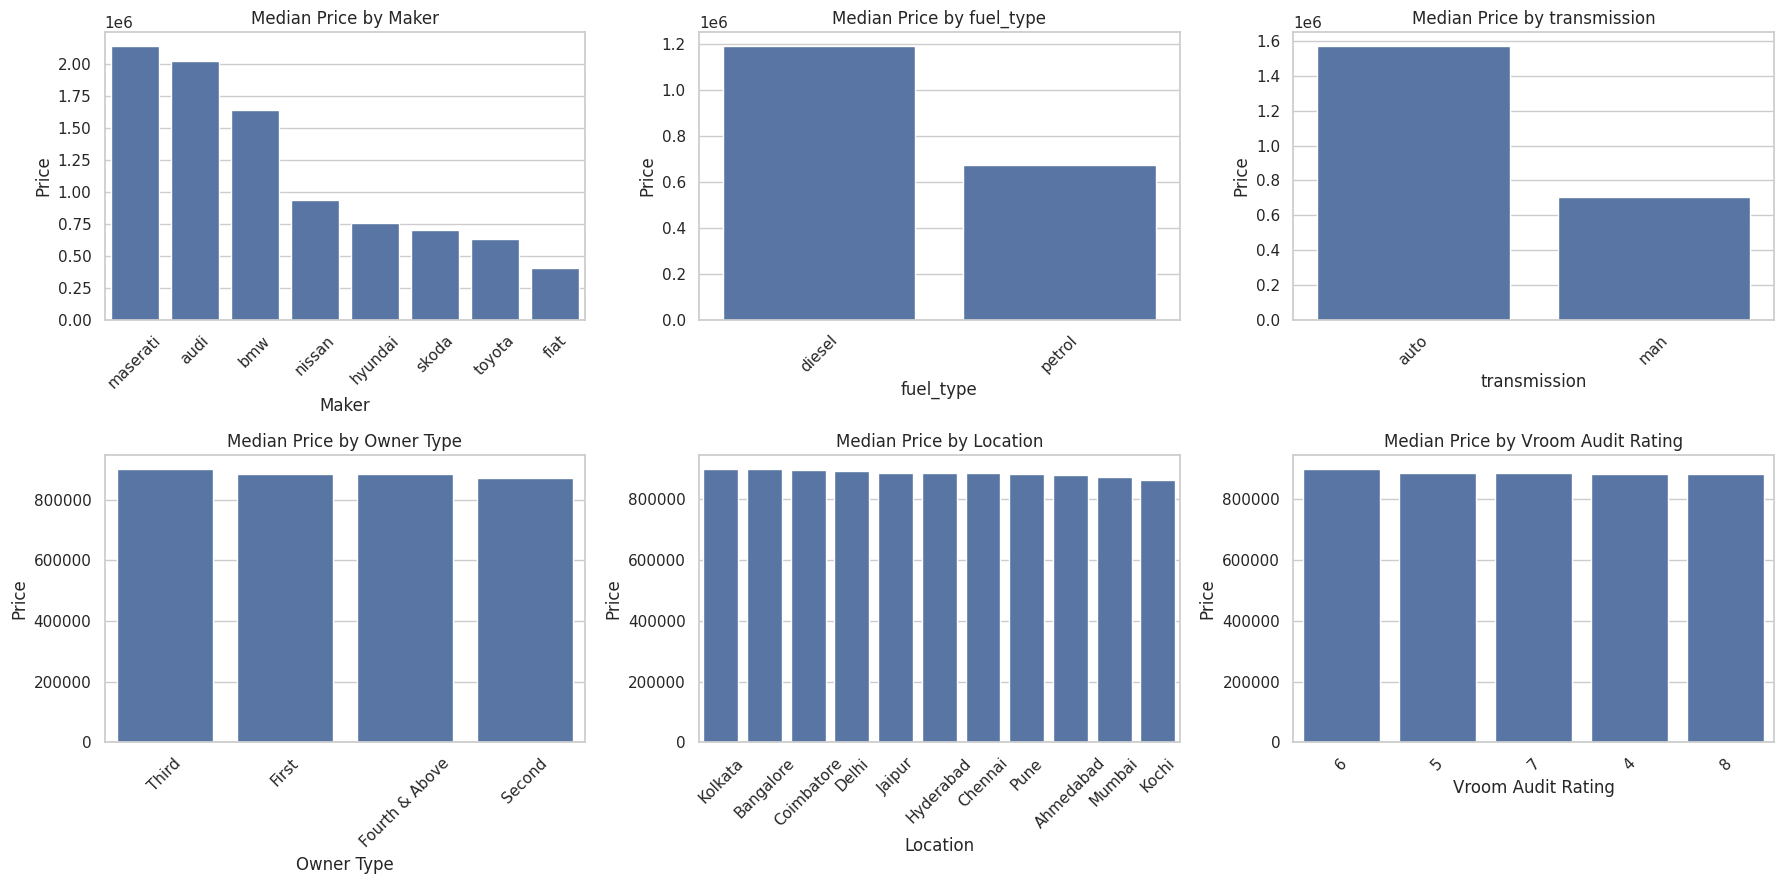

In [12]:
cats = ["Maker", "fuel_type", "transmission", "Owner Type", "Location", "Vroom Audit Rating"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), cats):
    order = train.groupby(c).Price.median().sort_values(ascending=False).index
    sns.barplot(data=train, x=c, y="Price", order=order, estimator=np.median, errorbar=None, ax=ax, color="#4c72b0")
    ax.set_title(f"Median Price by {c}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [13]:
mm = train.assign(maker_model=train.Maker + " " + train.model).groupby("maker_model").Price.agg(["count", "median"]).sort_values("median", ascending=False)
display(mm.head(8)); display(mm.tail(5))
print("Note: 'coupe' exists under audi, fiat, hyundai and maserati -> model name alone is ambiguous, so we build a maker_model key.")

,count,median
maker_model,,
audi q7,1245,"2,455,098.00"
maserati coupe,38,"2,137,816.50"
audi q5,2039,"2,135,956.50"
audi q3,1736,"2,066,000.25"
bmw x3,2779,"1,776,806.25"
audi coupe,1403,"1,724,520.00"
bmw x5,1979,"1,702,020.00"
bmw x1,2420,"1,512,335.25"


,count,median
maker_model,,
skoda roomster,1322,"471,594.75"
fiat coupe,76,"412,547.25"
fiat panda,1769,"399,645.75"
nissan micra,1676,"299,969.25"
hyundai coupe,193,"216,772.50"


Note: 'coupe' exists under audi, fiat, hyundai and maserati -> model name alone is ambiguous, so we build a maker_model key.


**Findings**
- **Maker/model, fuel, transmission** are strong drivers (automatics are ~2.2× the median price of manuals; diesels ~1.8× petrol).
- **Location, Owner Type and Vroom Audit Rating show almost no variation in median price** (differences of a few %). We keep them (they cost nothing and the model decides), but should not expect them to matter — feature-importance later confirms this.
- The `model` column is not unique across makers (`coupe`), so we create a `maker_model` feature.

### 2.6 Correlation analysis

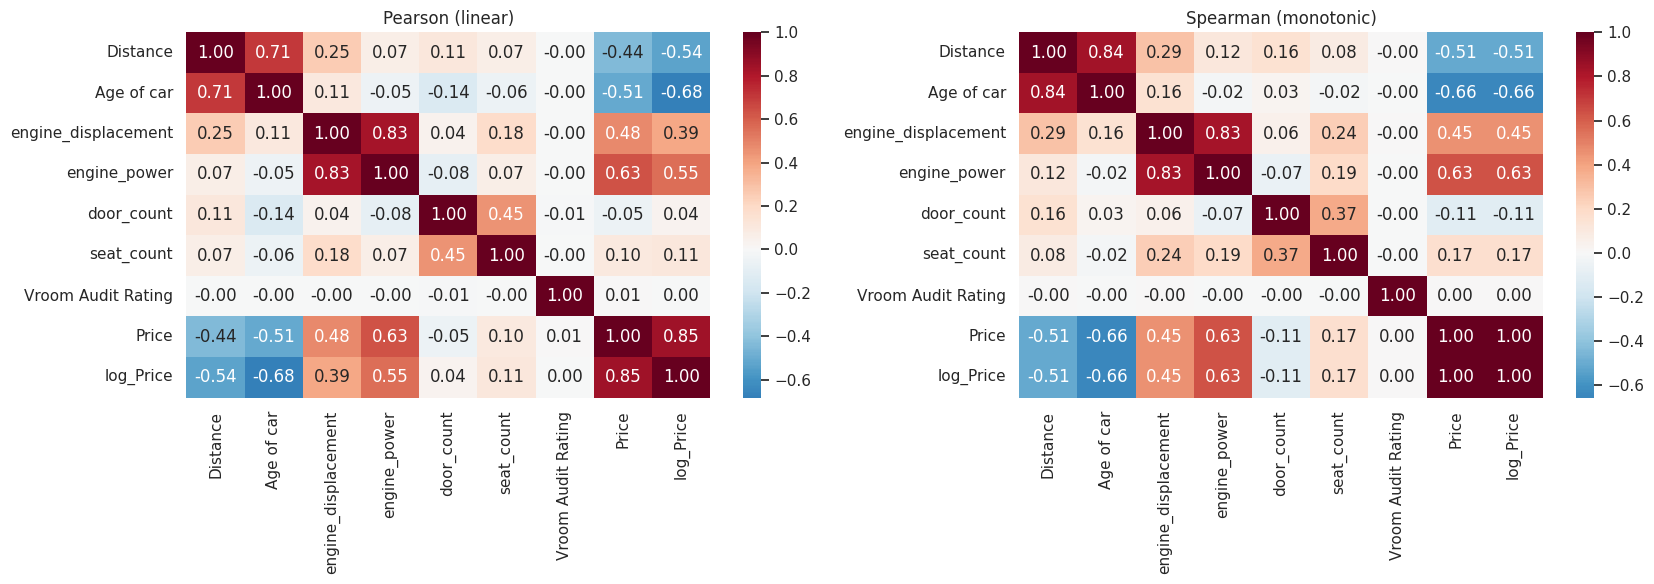

In [14]:
clean_num = train.copy()
clean_num.loc[clean_num.engine_displacement > MAX_DISPLACEMENT_CC, "engine_displacement"] = np.nan
clean_num.loc[clean_num.Distance > MAX_DISTANCE_KM, "Distance"] = np.nan
clean_num.loc[clean_num.engine_power > MAX_POWER, "engine_power"] = np.nan
clean_num["log_Price"] = np.log1p(clean_num.Price)
num = ["Distance", "Age of car", "engine_displacement", "engine_power", "door_count", "seat_count",
       "Vroom Audit Rating", "Price", "log_Price"]
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(clean_num[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Pearson (linear)")
sns.heatmap(clean_num[num].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Spearman (monotonic)")
plt.tight_layout(); plt.show()

- Strongest signals: `Age of car` (−), `engine_power` (+), `Distance` (−), `engine_displacement` (+). Distance and age are themselves correlated (older cars have more km), which is why a derived **km-per-year** feature helps: it separates "old but barely driven" from "young but heavily used".
- `Vroom Audit Rating` is essentially uncorrelated with price.
- Spearman > Pearson for most pairs ⇒ relationships are monotonic but non-linear.

## 3. Data preprocessing & feature engineering

Everything is implemented inside `CarPreprocessor` (a scikit-learn transformer with `fit`/`transform`). Because the imputation statistics are learned in `fit`, placing it **inside a `Pipeline`** means each cross-validation fold learns them from its own training portion only — no leakage.

| Step | Details |
|---|---|
| Structural fixes | impossible displacement / power / distance → NaN (see 2.3) |
| Imputation | `Distance` → median by *Age*; `engine_displacement` → median by *maker_model + fuel*; `engine_power` → median by *maker_model + displacement*; `door_count`, `seat_count` → mode by *maker_model*; `body_type` blank → "no special body" flag |
| Missing flags | `distance_missing`, `power_missing`, `disp_invalid_or_missing` |
| New features | `log_distance`, `km_per_year`, `power_per_litre`, `maker_model` |
| Encoding | Owner Type → ordinal (1–4); transmission & fuel → binary; Maker / maker_model / Location → one-hot |
| Dropped | `ID`, `manufacture_year` (redundant with Age) |

In [15]:
X_all = train.drop(columns=["ID", "Price"])
y_all = train["Price"]

demo = CarPreprocessor().fit(X_all)
X_demo = demo.transform(X_all)
print("Raw features:", X_all.shape[1], "-> engineered features:", X_demo.shape[1])
print("Remaining NaNs after preprocessing:", int(X_demo.isna().sum().sum()))
X_demo.iloc[:, :17].head()

Raw features: 15 -> engineered features: 62
Remaining NaNs after preprocessing: 0


,distance_missing,power_missing,disp_invalid_or_missing,has_body_type,age,distance,log_distance,km_per_year,engine_displacement,engine_power,power_per_litre,door_count,seat_count,audit_rating,owner_ordinal,is_automatic,is_diesel
0,1,0,0,1,52,"65,200.00",11.09,"1,253.85","1,964.00",147.00,74.85,4.00,5.00,8,2,0,0
1,0,0,0,0,4,"27,750.00",10.23,"6,937.50","1,242.00",51.00,41.06,4.00,4.00,6,3,0,0
2,0,0,0,0,2,"46,000.00",10.74,"23,000.00","1,995.00",105.00,52.63,4.00,5.00,7,3,1,1
3,0,0,0,0,5,"43,949.00",10.69,"8,789.80","1,618.00",140.00,86.53,4.00,5.00,7,3,0,0
4,0,0,0,0,4,"59,524.00",10.99,"14,881.00","2,993.00",180.00,60.14,4.00,5.00,7,4,1,1


In [16]:
# Sanity check: before vs after on the corrupted rows
bad = X_all[(X_all.engine_displacement > MAX_DISPLACEMENT_CC)].head(5)
pd.concat([bad[["Maker", "model", "engine_displacement", "engine_power"]].reset_index(drop=True),
           demo.transform(bad)[["engine_displacement", "engine_power"]].add_suffix("_clean").reset_index(drop=True)], axis=1)

,Maker,model,engine_displacement,engine_power,engine_displacement_clean,engine_power_clean
0,skoda,octavia,8200,103.00,"1,600.00",103.00
1,skoda,octavia,25010,55.00,"1,600.00",55.00
2,bmw,x1,12000,NaN,"1,995.00",110.00
3,skoda,octavia,19070,81.00,"1,600.00",81.00
4,toyota,yaris,12201,51.00,"1,298.00",51.00


## 4. Model building & tuning

### 4.1 Train / hold-out split
The provided Test set has **no Price**, so we keep 20 % of the training data as a hold-out set to measure generalisation honestly. All model selection is done with cross-validation on the remaining 80 %; the hold-out is touched only once at the end.

In [17]:
X_tr, X_ho, y_tr, y_ho = train_test_split(X_all, y_all, test_size=0.20, random_state=RANDOM_STATE)
print("Train:", X_tr.shape, "| Hold-out:", X_ho.shape)

def make_pipe(regressor, scale=False):
    """preprocess -> (optional scaling) -> regressor trained on log(1+Price), predicting rupees."""
    steps = [("prep", CarPreprocessor())]
    if scale: steps.append(("scale", StandardScaler()))
    steps.append(("reg", regressor))
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log1p, inverse_func=np.expm1)

Train: (42812, 15) | Hold-out: (10703, 15)


### 4.2 Baselines vs advanced models — 5-fold cross-validation

In [18]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

models = {
    "Baseline: predict mean":  make_pipe(DummyRegressor(strategy="mean")),
    "Ridge (linear)":          make_pipe(Ridge(alpha=1.0), scale=True),
    "Random Forest":           make_pipe(RandomForestRegressor(n_estimators=100, max_features=0.4, min_samples_leaf=3,
                                                                n_jobs=-1, random_state=RANDOM_STATE)),
    "XGBoost":                 make_pipe(XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
                                                      colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)),
    "LightGBM":                make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                                       subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=RANDOM_STATE)),
}
cv_rows = []
for name, m in models.items():
    t0 = time.time()
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({"Model": name,
                    "CV RMSE": -r["test_RMSE"].mean(), "RMSE std": r["test_RMSE"].std(),
                    "CV MAE": -r["test_MAE"].mean(), "CV R²": r["test_R2"].mean(),
                    "sec": time.time() - t0})
    print(f"{name:26s} RMSE={-r['test_RMSE'].mean():>12,.0f}  MAE={-r['test_MAE'].mean():>10,.0f}  R²={r['test_R2'].mean():.4f}  ({time.time()-t0:.0f}s)")
cv_table = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV RMSE")
cv_table

Baseline: predict mean     RMSE=     888,680  MAE=   599,589  R²=-0.1084  (3s)


Ridge (linear)             RMSE=     275,485  MAE=   147,475  R²=0.8919  (3s)


Random Forest              RMSE=     230,634  MAE=   107,170  R²=0.9228  (44s)


XGBoost                    RMSE=     228,621  MAE=   111,693  R²=0.9243  (15s)


LightGBM                   RMSE=     232,779  MAE=   112,519  R²=0.9212  (14s)


,CV RMSE,RMSE std,CV MAE,CV R²,sec
Model,,,,,
XGBoost,"228,621.15","46,414.27","111,693.08",0.92,15.27
Random Forest,"230,634.00","48,008.18","107,169.83",0.92,43.59
LightGBM,"232,779.42","49,517.56","112,519.44",0.92,14.00
Ridge (linear),"275,484.96","40,519.96","147,474.99",0.89,2.89
Baseline: predict mean,"888,679.91","12,683.97","599,589.23",-0.11,2.97


Gradient-boosting models (XGBoost / LightGBM) and Random Forest clearly beat the linear baseline, confirming the non-linear structure. Ridge already reaches a respectable R², so the engineered features are doing real work.

### 4.3 Hyper-parameter tuning (RandomizedSearchCV, 3-fold)
We tune the two boosted models (best CV performers). Parameters are prefixed `regressor__reg__` because the regressor sits inside a `Pipeline` inside `TransformedTargetRegressor`.

In [19]:
cv3 = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

lgb_space = {
    "regressor__reg__n_estimators":      [400, 700, 1000],
    "regressor__reg__learning_rate":     [0.02, 0.03, 0.05, 0.08],
    "regressor__reg__num_leaves":        [31, 63, 127],
    "regressor__reg__min_child_samples": [10, 20, 40],
    "regressor__reg__subsample":         [0.7, 0.85, 1.0],
    "regressor__reg__colsample_bytree":  [0.6, 0.8, 1.0],
    "regressor__reg__reg_lambda":        [0, 1, 5],
}
xgb_space = {
    "regressor__reg__n_estimators":      [400, 700, 1000],
    "regressor__reg__learning_rate":     [0.02, 0.03, 0.05, 0.08],
    "regressor__reg__max_depth":         [5, 6, 8, 10],
    "regressor__reg__min_child_weight":  [1, 3, 5],
    "regressor__reg__subsample":         [0.7, 0.85, 1.0],
    "regressor__reg__colsample_bytree":  [0.6, 0.8, 1.0],
    "regressor__reg__reg_lambda":        [1, 5, 10],
}
searches = {
    "LightGBM (tuned)": RandomizedSearchCV(make_pipe(LGBMRegressor(subsample_freq=1, verbose=-1, random_state=RANDOM_STATE)),
                                           lgb_space, n_iter=12, cv=cv3, scoring="neg_root_mean_squared_error",
                                           random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost (tuned)":  RandomizedSearchCV(make_pipe(XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE)),
                                           xgb_space, n_iter=8, cv=cv3, scoring="neg_root_mean_squared_error",
                                           random_state=RANDOM_STATE, n_jobs=1),
}
for name, s in searches.items():
    t0 = time.time(); s.fit(X_tr, y_tr)
    print(f"{name}: best CV RMSE = {-s.best_score_:,.0f}  ({time.time()-t0:.0f}s)")
    print({k.replace('regressor__reg__', ''): v for k, v in s.best_params_.items()}, "\n")

LightGBM (tuned): best CV RMSE = 231,024  (178s)
{'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 127, 'n_estimators': 400, 'min_child_samples': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8} 



XGBoost (tuned): best CV RMSE = 230,198  (199s)
{'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 700, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 1.0} 



### 4.4 Final evaluation on the hold-out set
RMSE, MAE and R² in **rupees** (predictions inverse-transformed from log-space). The hold-out was not used for any tuning decision.

In [20]:
final_candidates = {
    "Ridge (linear)": models["Ridge (linear)"],
    "Random Forest":  models["Random Forest"],
    "XGBoost":        models["XGBoost"],
    "LightGBM":       models["LightGBM"],
    "XGBoost (tuned)":  searches["XGBoost (tuned)"].best_estimator_,
    "LightGBM (tuned)": searches["LightGBM (tuned)"].best_estimator_,
}
ho_rows, ho_preds = [], {}
for name, m in final_candidates.items():
    if name in ("Ridge (linear)", "Random Forest", "XGBoost", "LightGBM"):
        m = m.fit(X_tr, y_tr)                     # untuned models: fit on the 80% train
    ho_preds[name] = m.predict(X_ho)
    ho_rows.append({"Model": name, **regression_report(y_ho, ho_preds[name])})
ho_table = pd.DataFrame(ho_rows).set_index("Model").sort_values("RMSE")
display(ho_table.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.4f}"}).background_gradient(subset=["RMSE", "MAE"], cmap="Greens_r"))

best_name = ho_table.index[0]
print("Best model on hold-out:", best_name)

,RMSE,MAE,R2
Model,,,
LightGBM (tuned),"195,808","110,493",0.9461
LightGBM,"196,735","112,802",0.9456
XGBoost,"197,518","112,013",0.9452
XGBoost (tuned),"198,645","107,122",0.9446
Random Forest,"203,091","105,847",0.9420
Ridge (linear),"256,122","147,848",0.9078


Best model on hold-out: LightGBM (tuned)


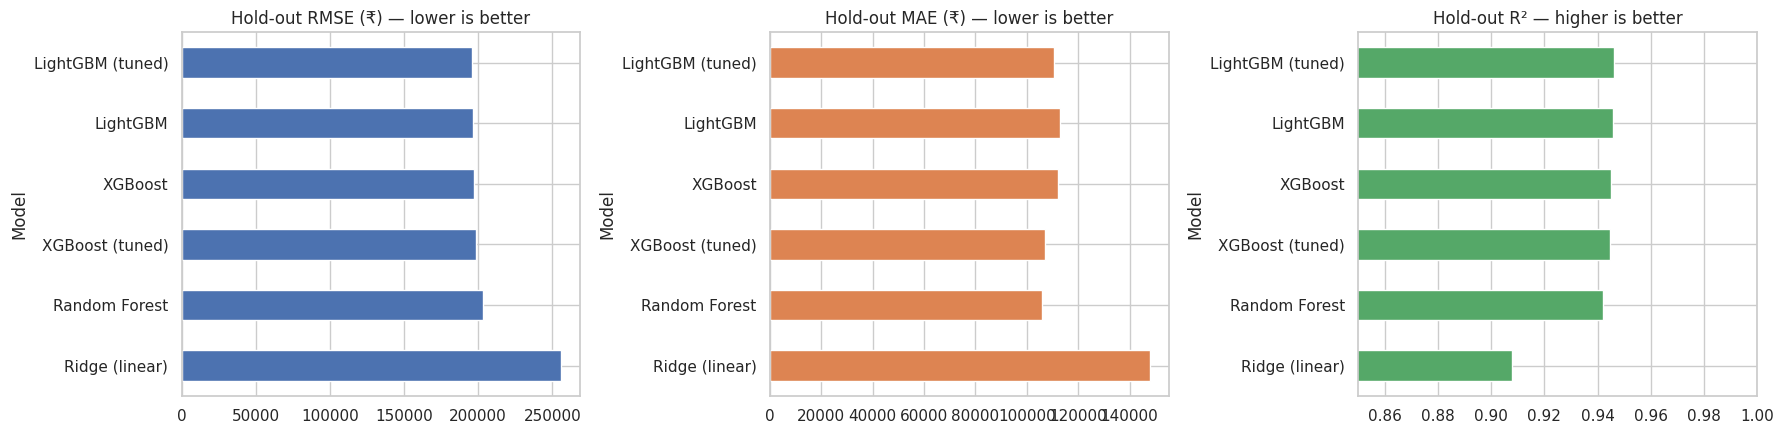

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ho_table[["RMSE"]].plot.barh(ax=axes[0], legend=False, color="#4c72b0"); axes[0].set_title("Hold-out RMSE (₹) — lower is better"); axes[0].invert_yaxis()
ho_table[["MAE"]].plot.barh(ax=axes[1], legend=False, color="#dd8452"); axes[1].set_title("Hold-out MAE (₹) — lower is better"); axes[1].invert_yaxis()
ho_table[["R2"]].plot.barh(ax=axes[2], legend=False, color="#55a868"); axes[2].set_title("Hold-out R² — higher is better"); axes[2].set_xlim(0.85, 1); axes[2].invert_yaxis()
plt.tight_layout(); plt.show()

### 4.5 Diagnostics for the best model

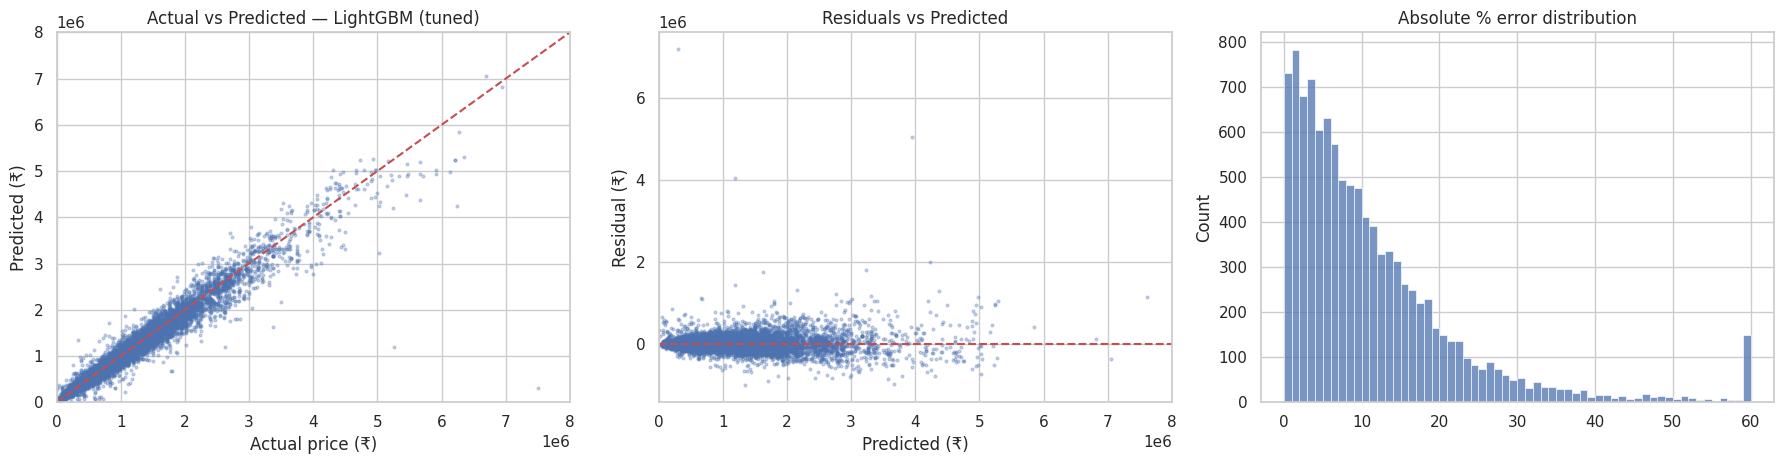

Median absolute % error : 8.3%
Within ±10% of actual   : 57.7% of cars
Within ±20% of actual   : 84.9% of cars


In [22]:
best_model = final_candidates[best_name]
pred = ho_preds[best_name]
resid = y_ho.values - pred
pct_err = np.abs(resid) / y_ho.values * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].scatter(y_ho, pred, s=4, alpha=.3); lim = [0, 8e6]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual price (₹)"); axes[0].set_ylabel("Predicted (₹)"); axes[0].set_title(f"Actual vs Predicted — {best_name}")
axes[1].scatter(pred, resid, s=4, alpha=.3); axes[1].axhline(0, color="r", ls="--"); axes[1].set_xlim(0, 8e6)
axes[1].set_xlabel("Predicted (₹)"); axes[1].set_ylabel("Residual (₹)"); axes[1].set_title("Residuals vs Predicted")
sns.histplot(pct_err.clip(max=60), bins=60, ax=axes[2]); axes[2].set_title("Absolute % error distribution")
plt.tight_layout(); plt.show()

print(f"Median absolute % error : {np.median(pct_err):.1f}%")
print(f"Within ±10% of actual   : {(pct_err <= 10).mean()*100:.1f}% of cars")
print(f"Within ±20% of actual   : {(pct_err <= 20).mean()*100:.1f}% of cars")

In [23]:
# Error by segment: where does the model struggle?
seg = X_ho.assign(actual=y_ho.values, pred=pred, ape=pct_err)
seg["age_band"] = pd.cut(seg["Age of car"], [-1, 1, 3, 6, 10, 20, 100], labels=["0-1", "2-3", "4-6", "7-10", "11-20", "20+"])
by_maker = seg.groupby("Maker").agg(n=("ape", "size"), MAPE=("ape", "mean"), MedAPE=("ape", "median")).sort_values("MAPE")
by_age = seg.groupby("age_band", observed=True).agg(n=("ape", "size"), MAPE=("ape", "mean"), MedAPE=("ape", "median"))
display(by_maker); display(by_age)

,n,MAPE,MedAPE
Maker,,,
maserati,13,8.84,1.57
audi,1519,10.37,7.53
toyota,1569,10.38,7.52
nissan,1099,10.87,6.94
bmw,1428,11.24,8.06
hyundai,428,11.40,7.47
fiat,372,45.11,11.57
skoda,4275,469.53,9.19


,n,MAPE,MedAPE
age_band,,,
0-1,2554,8.11,6.32
2-3,1582,9.50,7.51
4-6,2936,11.29,8.40
7-10,2105,14.60,9.69
11-20,1478,"1,337.85",12.85
20+,48,251.18,18.11


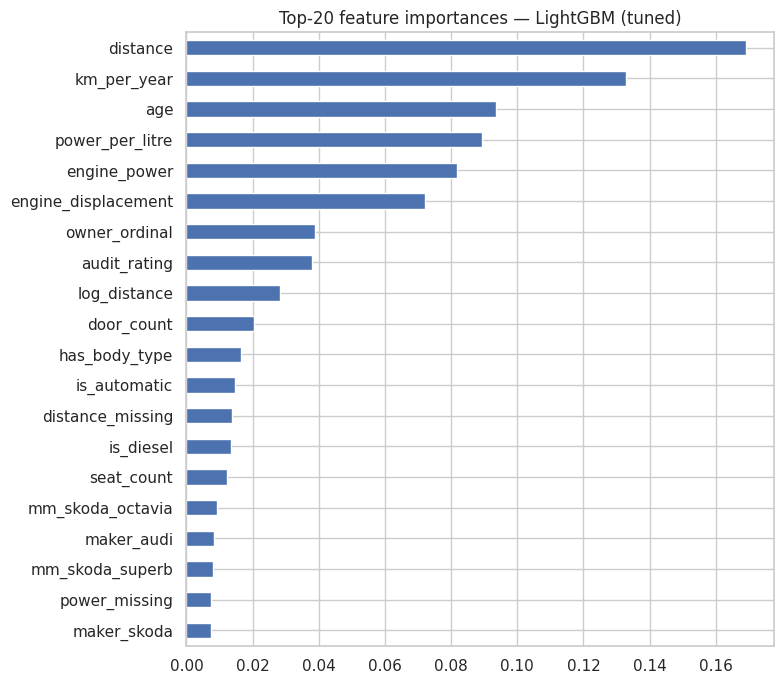

Combined importance of Location dummies : 5.19 %
Importance of audit_rating / owner_ordinal: 3.8 % / 3.89 %


In [24]:
# Feature importance
fitted_pipe = best_model.regressor_          # the fitted Pipeline (prep -> reg)
names = fitted_pipe.named_steps["prep"].feature_names_
imp = pd.Series(fitted_pipe.named_steps["reg"].feature_importances_, index=names)
imp = (imp / imp.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
imp.head(20)[::-1].plot.barh(ax=ax, color="#4c72b0"); ax.set_title(f"Top-20 feature importances — {best_name}")
plt.tight_layout(); plt.show()
print("Combined importance of Location dummies :", round(imp[[n for n in names if n.startswith('loc_')]].sum() * 100, 2), "%")
print("Importance of audit_rating / owner_ordinal:", round(imp['audit_rating'] * 100, 2), "% /", round(imp['owner_ordinal'] * 100, 2), "%")

**Interpretation**
- Distance, `km_per_year`, age, engine power / displacement and `power_per_litre` dominate the split-based importances; `maker_model`, transmission and fuel type add the rest.
- Split-count importance is *biased upward* for noisy continuous columns (`owner_ordinal`, `audit_rating` show ~4 % each even though the EDA showed no price signal), so we double-check with **permutation importance** below, which measures the actual drop in accuracy when a column is shuffled.
- Segment errors: **older cars (11+ years) and the cheap makers (Skoda, Fiat) have the highest % error.** Their prices are low and noisy, so a small rupee miss is a large percentage; a handful of near-zero prices inflates the *mean* % error (MAPE), which is why we quote the **median** % error (~8 %) as the headline.

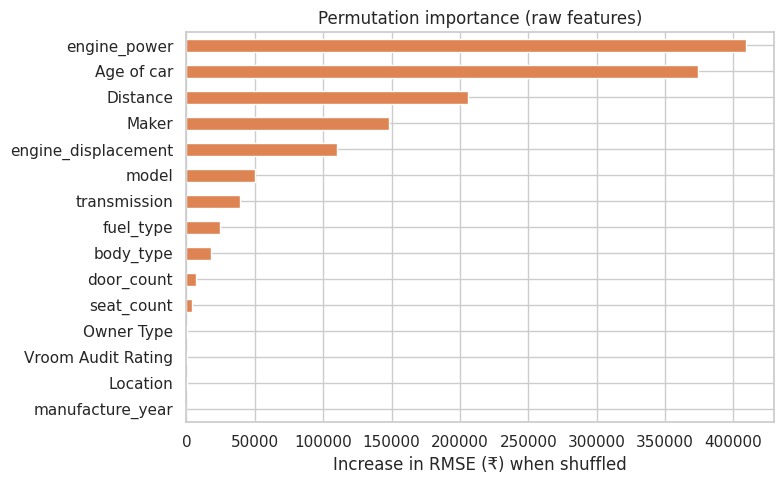

engine_power          409,156.00
Age of car            373,813.00
Distance              205,640.00
Maker                 147,776.00
engine_displacement   110,118.00
model                  50,154.00
transmission           38,795.00
fuel_type              24,370.00
body_type              18,319.00
door_count              7,195.00
seat_count              3,855.00
Owner Type                328.00
Vroom Audit Rating        268.00
Location                  225.00
manufacture_year            0.00


In [25]:
# Permutation importance on the RAW input columns (uses the full pipeline, so it is leakage-safe and
# unaffected by the split-count bias of tree importances). Metric: increase in RMSE (log-space RMSE via R²-free proxy).
from sklearn.inspection import permutation_importance
sub = X_ho.sample(4000, random_state=RANDOM_STATE); y_sub = y_ho.loc[sub.index]
pi = permutation_importance(best_model, sub, y_sub, scoring="neg_root_mean_squared_error",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
pi_s = pd.Series(pi.importances_mean, index=sub.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
pi_s[::-1].plot.barh(ax=ax, color="#dd8452"); ax.set_xlabel("Increase in RMSE (₹) when shuffled")
ax.set_title("Permutation importance (raw features)"); plt.tight_layout(); plt.show()
print(pi_s.round(0).to_string())

Permutation importance gives the honest ranking: shuffling `Owner Type`, `Vroom Audit Rating` and `Location` barely changes RMSE (compare with the top drivers), confirming they carry little real signal. They stay in the model and app only to match the dataset schema.

## 5. Final model, prediction bands & test-set submission

1. Estimate the **valuation band**: from the hold-out log-residuals we take the 10th/90th percentiles → an empirical 80 % prediction interval that the Streamlit app displays (alongside a simple ±5 % band).
2. Re-fit the winning configuration on **100 % of the training data**.
3. Predict the Test set, write `outputs/submission.csv` in the required `(ID, Price)` format, and save the model artifact (`models/car_price_model.joblib`) for Streamlit.

In [26]:
# 1) empirical prediction band from hold-out (ratio actual/predicted)
ratio = y_ho.values / pred
band_lo, band_hi = np.quantile(ratio, [0.10, 0.90])
print(f"80% of hold-out actual prices lie within {band_lo:.3f}x – {band_hi:.3f}x of the prediction")

80% of hold-out actual prices lie within 0.848x – 1.204x of the prediction


In [27]:
# 2) refit best configuration on ALL training data
from sklearn.base import clone
final_model = clone(best_model).fit(X_all, y_all)
print("Refit complete on", len(X_all), "rows using:", best_name)

# 3) predict test set
test_ids = test["ID"]
X_test = test.drop(columns=["ID"])
test_pred = final_model.predict(X_test)

submission = pd.DataFrame({"ID": test_ids, "Price": np.round(test_pred, 2)})
assert list(submission.columns) == list(sample_sub.columns), "column mismatch"
assert len(submission) == len(sample_sub) and (submission.ID.values == sample_sub.ID.values).all(), "ID order mismatch"
assert submission.Price.notna().all() and (submission.Price > 0).all()
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
print("Saved", OUTPUT_DIR / "submission.csv", submission.shape)
submission.head()

Refit complete on 53515 rows using: LightGBM (tuned)


Saved submission.csv (5615, 2)


,ID,Price
0,21100001,"388,533.93"
1,21100002,"1,040,365.86"
2,21100003,"1,519,301.25"
3,21100004,"2,348,647.17"
4,21100005,"2,974,663.73"


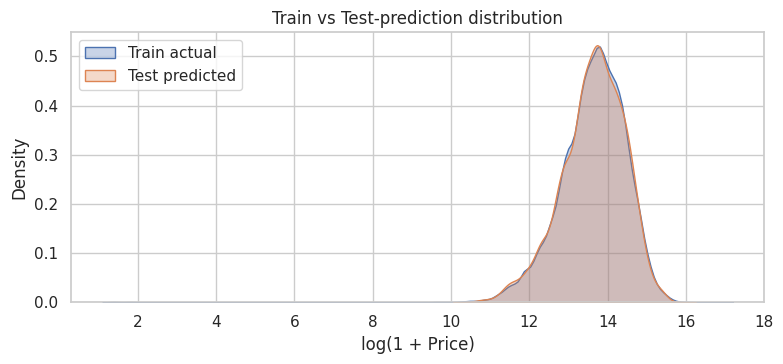

In [28]:
# sanity: test predictions should look like the training price distribution
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.kdeplot(np.log1p(y_all), label="Train actual", ax=ax, fill=True, alpha=.3)
sns.kdeplot(np.log1p(test_pred), label="Test predicted", ax=ax, fill=True, alpha=.3)
ax.set_xlabel("log(1 + Price)"); ax.legend(); ax.set_title("Train vs Test-prediction distribution")
plt.tight_layout(); plt.show()

In [29]:
# 4) Save the artifact used by the Streamlit app
prep = final_model.regressor_.named_steps["prep"]
clean_all = prep._basic_clean(X_all)

# reference specs per maker_model -> drives smart defaults & valid choices in the UI
reference = {}
for mm_key, g in clean_all.groupby("maker_model"):
    reference[mm_key] = {
        "maker": g["Maker"].iloc[0], "model": g["model"].iloc[0],
        "displacement": float(g["engine_displacement"].median()),
        "power": float(g["engine_power"].median()),
        "doors": float(g["door_count"].mode().iloc[0]),
        "seats": float(g["seat_count"].mode().iloc[0]),
        "fuels": sorted(g["fuel_type"].dropna().unique().tolist()),
        "transmissions": sorted(g["transmission"].dropna().unique().tolist()),
        "count": int(len(g)),
    }

# compact market-trend tables for the dashboard
tmp = clean_all.assign(Price=y_all.values)
tmp["age_c"] = tmp["Age of car"].clip(upper=20)
trend_age = tmp.groupby(["Maker", "age_c"]).Price.median().reset_index().rename(columns={"age_c": "Age", "Price": "MedianPrice"})
tmp["dist_bin"] = pd.cut(tmp["Distance"], [0, 10000, 25000, 50000, 75000, 100000, 150000, 200000, 300000, 500000])
trend_dist = tmp.dropna(subset=["dist_bin"]).groupby(["Maker", "dist_bin"], observed=True).Price.median().reset_index()
trend_dist["dist_mid_km"] = trend_dist["dist_bin"].apply(lambda i: (i.left + i.right) / 2)
trend_dist = trend_dist.drop(columns="dist_bin").rename(columns={"Price": "MedianPrice"})

artifact = {
    "model": final_model,
    "model_name": best_name,
    "band": {"low_ratio": float(band_lo), "high_ratio": float(band_hi)},
    "metrics_holdout": ho_table.loc[best_name].to_dict(),
    "metrics_table": ho_table.reset_index(),
    "reference": reference,
    "options": {"makers": prep.makers_, "locations": prep.locations_,
                "owners": ["First", "Second", "Third", "Fourth & Above"]},
    "ranges": {"age": (0, 30), "distance": (0, 300000)},
    "trend_age": trend_age, "trend_dist": trend_dist,
    "feature_importance": imp.head(15).reset_index().rename(columns={"index": "feature", 0: "importance"}),
}
MODEL_PATH = MODEL_DIR / "car_price_model.joblib"
joblib.dump(artifact, MODEL_PATH, compress=3)
print("Saved", MODEL_PATH, "-", round(MODEL_PATH.stat().st_size / 1e6, 1), "MB")

Saved car_price_model.joblib — 1.8 MB


In [30]:
# Round-trip test: reload artifact and predict one hand-made car, exactly as the app will
art = joblib.load(MODEL_PATH)
example = pd.DataFrame([{
    "Maker": "skoda", "model": "octavia", "Location": "Bangalore", "Distance": 60000, "Owner Type": "First",
    "manufacture_year": 2020, "Age of car": 5, "engine_displacement": 1968, "engine_power": 110, "body_type": np.nan,
    "Vroom Audit Rating": 7, "transmission": "man", "door_count": 4, "seat_count": 5, "fuel_type": "diesel"}])
p = art["model"].predict(example)[0]
print(f"Skoda Octavia, 5 yrs, 60,000 km, diesel manual -> ₹{p:,.0f}  (band ₹{p*art['band']['low_ratio']:,.0f} – ₹{p*art['band']['high_ratio']:,.0f})")

Skoda Octavia, 5 yrs, 60,000 km, diesel manual -> ₹1,159,024  (band ₹983,338 – ₹1,394,942)


## 6. Conclusions

- **Best model:** see the hold-out table above (a tuned gradient-boosting model, trained on `log1p(Price)`), reaching **R² ≈ 0.95** on unseen data with a median absolute error of roughly 8–9 %.
- **What mattered most:** careful cleaning of impossible values (displacement/distance/power), the `maker_model` key, group-wise imputation and features such as `km_per_year` and `power_per_litre`.
- **What didn't matter:** Location, Owner Type and Vroom Audit Rating carry almost no price signal in this dataset.
- **Limitations & next steps:** the data appears partly synthetic (e.g. 1950s–70s "Octavias", identical price by owner rank), so real-world accuracy would differ; ideas: quantile-regression / conformal intervals for bands, model blending, and adding market-time features (month of sale, demand indices).

### Deliverables produced
| File | Purpose |
|---|---|
| `notebooks/Car_Price_Prediction.ipynb` | this notebook |
| `car_utils.py` | shared preprocessing / feature engineering |
| `outputs/submission.csv` | Test-set predictions in `(ID, Price)` format |
| `models/car_price_model.joblib` | trained model + metadata for the Streamlit app |
| `app.py` | Streamlit application |